In [1]:
from pathlib import Path
import pandas as pd
import re
import numpy as np
import scipy.stats as stats
parent_dir = Path.cwd().parent.parent

file_path = parent_dir / "data" / "data_durasi.csv"
df = pd.read_csv(file_path, delimiter=",", encoding="utf-8")
print(df.head())


             Durasi    Hari     Jam
0          53 detik   Jumat  JAM 10
1  1 menit 50 detik   Jumat  JAM 10
2   1 menit 6 detik   Jumat  JAM 10
3          47 detik  Selasa  JAM 10
4          20 detik  Selasa  JAM 10


In [2]:
def konversi_durasi(teks):
    teks = str(teks).lower().strip()

    menit = re.search(r'(\d+)\s*menit', teks)
    detik = re.search(r'(\d+)\s*detik', teks)

    total_detik = 0

    if menit:
        total_detik += int(menit.group(1)) * 60

    if detik:
        total_detik += int(detik.group(1))

    return total_detik

df["Durasi"] = df["Durasi"].apply(konversi_durasi)
print(df.head())

   Durasi    Hari     Jam
0      53   Jumat  JAM 10
1     110   Jumat  JAM 10
2      66   Jumat  JAM 10
3      47  Selasa  JAM 10
4      20  Selasa  JAM 10


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Durasi  52 non-null     int64
 1   Hari    52 non-null     str  
 2   Jam     52 non-null     str  
dtypes: int64(1), str(2)
memory usage: 1.3 KB


In [4]:
q1 = np.percentile(df["Durasi"], 25)
q3 = np.percentile(df["Durasi"], 75)
iqr = q3 - q1
batas_wajar = q3 + (1.5 * iqr)
print(f"Batas wajar: {batas_wajar}, IQR: {iqr}, Q1: {q1}, Q3: {q3}")

Batas wajar: 367.0, IQR: 127.0, Q1: 49.5, Q3: 176.5


In [5]:
kandidat = [
    ('Eksponensial', stats.expon),
    ('Normal', stats.norm),
    ('Uniform', stats.uniform)
]


In [6]:
hasil_uji = []
for nama, dist in kandidat:
    # 1. dist.fit() mencari parameter terbaik (loc = posisi awal, scale = parameter bentuk)
    params = dist.fit(df["Durasi"])
    
    # 2. Uji Kolmogorov-Smirnov (Mengukur selisih kurva teoretis vs data lapangan)
    ks_stat, p_val = stats.kstest(df["Durasi"], dist.cdf, args=params)
    
    # 3. Kriteria Ilmiah: P-Value > 0.05 artinya data LAPANGAN COCOK DENGAN RUMUS (Diterima)
    status = "COCOK (P > 0.05)" if p_val > 0.05 else "DITOLAK (P < 0.05)"
    
    params_str = ", ".join([f"{p:.2f}" for p in params])
    print(f"{nama:<22} | {params_str:<25} | {ks_stat:>12.4f}  | {p_val:>8.4f}  | {status}")
    
    hasil_uji.append({'nama': nama, 'dist': dist, 'params': params, 'ks': ks_stat, 'pval': p_val})

terbaik = max(hasil_uji, key=lambda x: x['pval'])

print(f"\n💡 KESIMPULAN        :")
print(f"   Distribusi Terpilih : DISTRIBUSI {terbaik['nama'].upper()}")
print(f"   Alasan Statistik    : Nilai P-Value paling tinggi ({terbaik['pval']:.4f} > 0.05).")
print(f"   Penerapan di Koding : Di script simulasi 04_kasus_uin_bilis.py, kita harus menggunakan:")
print(f"                         `np.random.exponential(scale={terbaik['params'][1]:.2f})`!")

Eksponensial           | 14.00, 117.98             |       0.1151  |   0.4620  | COCOK (P > 0.05)
Normal                 | 131.98, 121.43            |       0.2257  |   0.0083  | DITOLAK (P < 0.05)
Uniform                | 14.00, 504.00             |       0.4728  |   0.0000  | DITOLAK (P < 0.05)

💡 KESIMPULAN        :
   Distribusi Terpilih : DISTRIBUSI EKSPONENSIAL
   Alasan Statistik    : Nilai P-Value paling tinggi (0.4620 > 0.05).
   Penerapan di Koding : Di script simulasi 04_kasus_uin_bilis.py, kita harus menggunakan:
                         `np.random.exponential(scale=117.98)`!


## Visualisasi Diagnostik Distribusi

Uji Kolmogorov-Smirnov sudah memberi keputusan numerik, tetapi keputusan itu sebaiknya **dilihat** juga secara visual. Perlu ditegaskan bahwa `Durasi` di sini adalah **lama seseorang berada di kantin**, bukan waktu pelayanan. Tiga panel berikut membandingkan data lapangan dengan model eksponensial yang di-`fit` pada sel sebelumnya:

| Panel | Yang dibandingkan | Cara membaca |
| --- | --- | --- |
| **(a)** Histogram vs PDF | Sebaran data vs kurva kepadatan eksponensial | Kurva merah harus mengikuti puncak dan ekor histogram. |
| **(b)** CDF empiris vs teoretis | Proporsi kumulatif data vs model | Jarak vertikal terbesar antar-kurva adalah statistik **D**; semakin kecil, semakin cocok. |
| **(c)** Q-Q plot | Kuantil data vs kuantil teoretis | Titik yang menempel pada garis `y = x` berarti data mengikuti distribusi tersebut. |

Semua parameter pada grafik berasal langsung dari hasil `stats.expon.fit()` (`loc` dan `scale`), jadi tidak ada asumsi tambahan.

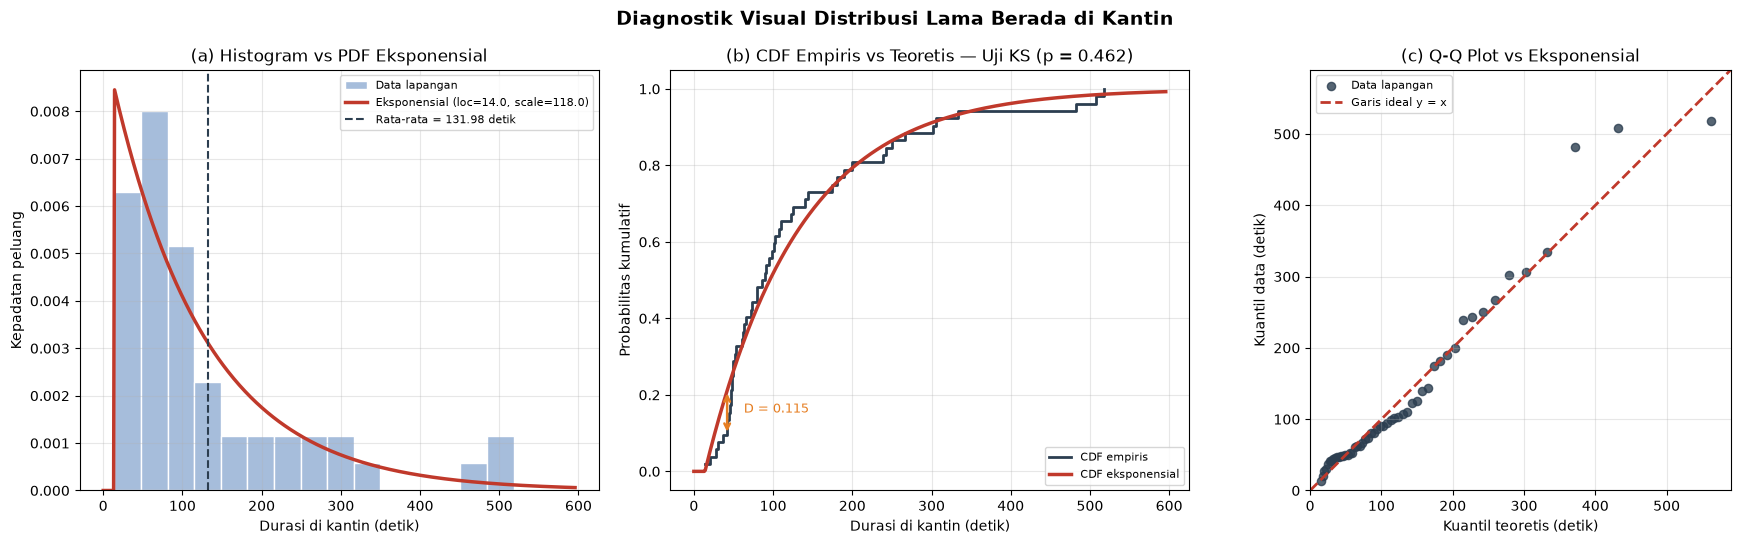

In [7]:
import matplotlib.pyplot as plt

params_exp = terbaik["params"]          # (loc, scale) hasil fit eksponensial
n = len(df)
x = np.linspace(0, df["Durasi"].max() * 1.15, 500)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) Histogram data vs PDF teoretis
ax = axes[0]
ax.hist(df["Durasi"], bins=15, density=True, color="#a6bddb",
        edgecolor="white", label="Data lapangan")
ax.plot(x, stats.expon.pdf(x, *params_exp), color="#c0392b", lw=2.5,
        label=f"Eksponensial (loc={params_exp[0]:.1f}, scale={params_exp[1]:.1f})")
ax.axvline(df["Durasi"].mean(), color="#2c3e50", ls="--", lw=1.5,
           label=f"Rata-rata = {df['Durasi'].mean():.2f} detik")
ax.set_title("(a) Histogram vs PDF Eksponensial")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Kepadatan peluang")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) CDF empiris vs CDF teoretis
ax = axes[1]
x_urut = np.sort(df["Durasi"].values)
cdf_teori = stats.expon.cdf(x_urut, *params_exp)
emp_atas = np.arange(1, n + 1) / n
emp_bawah = np.arange(0, n) / n

d_plus = emp_atas - cdf_teori
d_minus = cdf_teori - emp_bawah
if d_plus.max() >= d_minus.max():
    i_ks = int(np.argmax(d_plus))
    y_data = emp_atas[i_ks]
else:
    i_ks = int(np.argmax(d_minus))
    y_data = emp_bawah[i_ks]
d_ks = max(d_plus.max(), d_minus.max())

ax.step(x_urut, emp_atas, where="post", color="#2c3e50", lw=2,
        label="CDF empiris")
ax.plot(x, stats.expon.cdf(x, *params_exp), color="#c0392b", lw=2.5,
        label="CDF eksponensial")
ax.annotate("", xy=(x_urut[i_ks], y_data),
            xytext=(x_urut[i_ks], cdf_teori[i_ks]),
            arrowprops=dict(arrowstyle="<->", color="#e67e22", lw=1.8))
ax.annotate(f"D = {d_ks:.3f}",
            xy=(x_urut[i_ks], (y_data + cdf_teori[i_ks]) / 2),
            xytext=(12, 0), textcoords="offset points",
            color="#e67e22", fontsize=9)
ax.set_title(f"(b) CDF Empiris vs Teoretis — Uji KS (p = {terbaik['pval']:.3f})")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Probabilitas kumulatif")
ax.legend(loc="lower right", fontsize=8)
ax.grid(alpha=0.3)

# (c) Q-Q plot
ax = axes[2]
probs = (np.arange(1, n + 1) - 0.5) / n
kuantil_teori = stats.expon.ppf(probs, *params_exp)
ax.scatter(kuantil_teori, x_urut, s=35, color="#2c3e50",
           alpha=0.8, label="Data lapangan")
batas = [0, max(kuantil_teori.max(), x_urut.max()) * 1.05]
ax.plot(batas, batas, color="#c0392b", ls="--", lw=2, label="Garis ideal y = x")
ax.set_xlim(batas)
ax.set_ylim(batas)
ax.set_aspect("equal")
ax.set_title("(c) Q-Q Plot vs Eksponensial")
ax.set_xlabel("Kuantil teoretis (detik)")
ax.set_ylabel("Kuantil data (detik)")
ax.legend(loc="upper left", fontsize=8)
ax.grid(alpha=0.3)

fig.suptitle("Diagnostik Visual Distribusi Lama Berada di Kantin",
             fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### Interpretasi Hasil Visual

- **Panel (a)** — kurva eksponensial mengikuti histogram dengan baik: kepadatan tertinggi berada pada durasi pendek, lalu meluruh ke kanan. Nilai `loc = 14` adalah lama tinggal minimum, sedangkan `scale = 117,98` adalah rata-rata tambahan waktu setelah 14 detik. Jadi rata-rata lama seseorang berada di kantin adalah **14 + 117,98 ≈ 131,98 detik (≈ 2 menit 12 detik)**.
- **Panel (b)** — CDF empiris hampir menempel pada CDF eksponensial. Selisih vertikal terbesar hanya **D ≈ 0,115** (di durasi 42 detik) dengan p-value **0,462 > 0,05**. Artinya kita **gagal menolak H₀**: tidak ada bukti statistik bahwa lama berada di kantin menyimpang dari distribusi eksponensial.
- **Panel (c)** — titik-titik mengikuti garis `y = x` hampir sepanjang rentang. Penyimpangan kecil di ekor kanan (durasi > 350 detik) wajar karena sampel hanya 52 observasi dan tidak membentuk pola melengkung yang sistematis.

**Implikasi untuk simulasi:** lama seseorang berada di kantin dapat dibangkitkan dengan `np.random.exponential(scale=117.98) + 14`, atau ekuivalen dengan `stats.expon.rvs(loc=14, scale=117.98, size=n)`. Sifat *memoryless* distribusi eksponensial berarti sisa waktu seseorang di kantin tidak bergantung pada sudah berapa lama ia berada di sana — asumsi ini didukung data, meskipun secara perilaku tetap perlu diuji lebih lanjut.

> Catatan: p-value yang tinggi **bukan bukti** bahwa data benar-benar eksponensial, melainkan hanya menunjukkan bahwa pada ukuran sampel ini tidak cukup bukti untuk menolaknya.

## Simulasi Kunjungan Kantin

Setelah pola lama kunjungan diketahui, langkah berikutnya adalah **membangkitkan data baru** dari pola tersebut. Inilah inti simulasi: kita tidak lagi memakai 52 data asli, tetapi membuat 1.000 kunjungan acak dengan aturan yang sama, yaitu batas bawah 14 detik dan tambahan waktu rata-rata 117,98 detik.

Hasil simulasi kemudian dibandingkan dengan data asli untuk memastikan bahwa simulasi masuk akal. Karena memakai angka acak, hasil setiap kali dijalankan bisa berbeda. `np.random.seed(42)` dipakai agar hasil di notebook ini dapat diulang persis.

In [13]:
import matplotlib.pyplot as plt

np.random.seed(42)

n_sim = 1000
loc_exp, scale_exp = terbaik["params"]

# Bangkitkan lama kunjungan: batas bawah 14 detik + tambahan acak
durasi_sim = np.random.exponential(scale=scale_exp, size=n_sim) + loc_exp

ringkasan = pd.DataFrame({
    "Data asli": [len(df), df["Durasi"].mean(), df["Durasi"].median(),
                  df["Durasi"].min(), df["Durasi"].max()],
    "Simulasi": [n_sim, durasi_sim.mean(), np.median(durasi_sim),
                 durasi_sim.min(), durasi_sim.max()],
}, index=["Jumlah data", "Rata-rata (detik)", "Nilai tengah (detik)",
          "Tercepat (detik)", "Terlama (detik)"])

print("Ringkasan hasil simulasi:")
print(ringkasan.round(2).to_string())
print("\nProporsi kunjungan yang selesai dalam batas waktu tertentu:")
for batas in (120, 180, 300):
    asli = (df["Durasi"] <= batas).mean() * 100
    sim = (durasi_sim <= batas).mean() * 100
    print(f"  ≤ {batas // 60} menit : data asli {asli:5.1f}% | simulasi {sim:5.1f}%")

Ringkasan hasil simulasi:
                      Data asli  Simulasi
Jumlah data               52.00   1000.00
Rata-rata (detik)        131.98    128.74
Nilai tengah (detik)      88.00     95.03
Tercepat (detik)          14.00     14.55
Terlama (detik)          518.00    978.19

Proporsi kunjungan yang selesai dalam batas waktu tertentu:
  ≤ 2 menit : data asli  65.4% | simulasi  60.4%
  ≤ 3 menit : data asli  75.0% | simulasi  76.2%
  ≤ 5 menit : data asli  88.5% | simulasi  91.4%


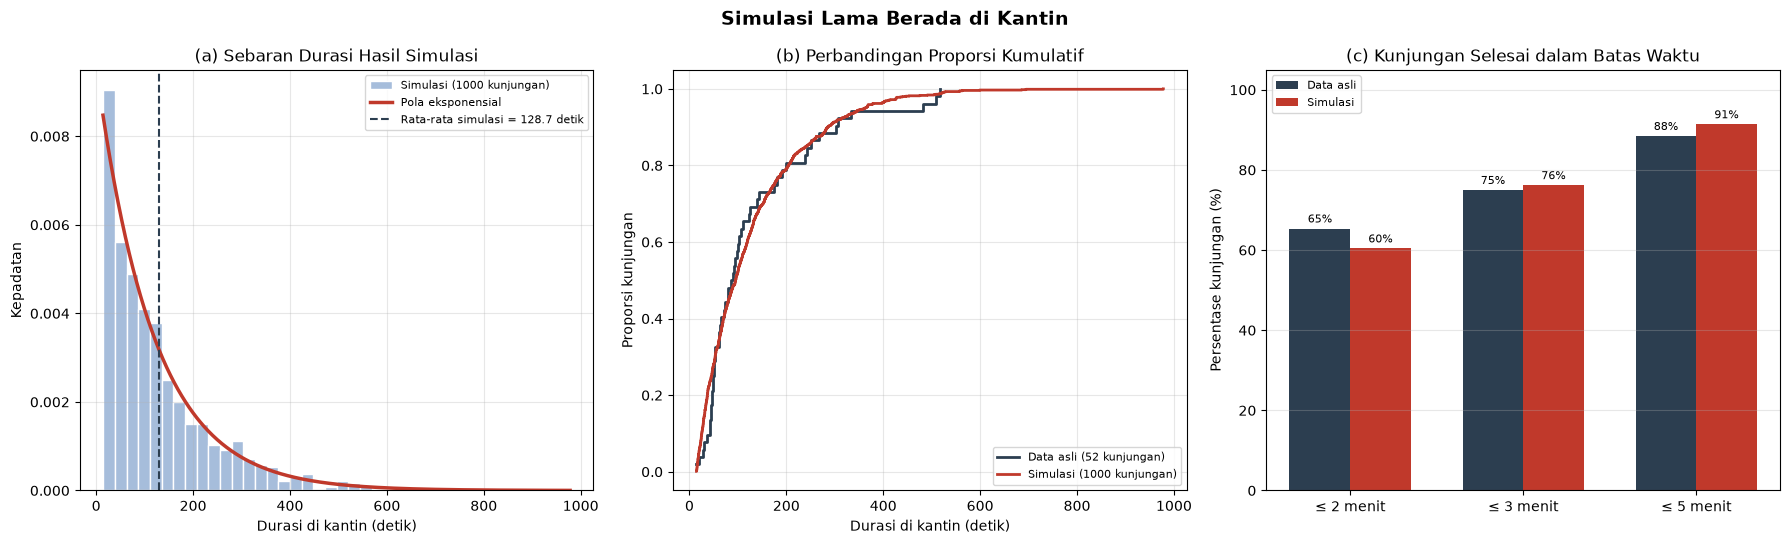

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# (a) Sebaran durasi simulasi
ax = axes[0]
ax.hist(durasi_sim, bins=40, density=True, color="#a6bddb",
        edgecolor="white", label=f"Simulasi ({n_sim} kunjungan)")
x_sim = np.linspace(loc_exp, durasi_sim.max(), 500)
ax.plot(x_sim, stats.expon.pdf(x_sim, loc=loc_exp, scale=scale_exp),
        color="#c0392b", lw=2.5, label="Pola eksponensial")
ax.axvline(durasi_sim.mean(), color="#2c3e50", ls="--", lw=1.5,
           label=f"Rata-rata simulasi = {durasi_sim.mean():.1f} detik")
ax.set_title("(a) Sebaran Durasi Hasil Simulasi")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Kepadatan")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) Perbandingan proporsi kumulatif
ax = axes[1]
for data, label, warna in [
    (df["Durasi"], "Data asli (52 kunjungan)", "#2c3e50"),
    (durasi_sim, f"Simulasi ({n_sim} kunjungan)", "#c0392b"),
]:
    urut = np.sort(data)
    proporsi = np.arange(1, len(urut) + 1) / len(urut)
    ax.step(urut, proporsi, where="post", color=warna, lw=2, label=label)
ax.set_title("(b) Perbandingan Proporsi Kumulatif")
ax.set_xlabel("Durasi di kantin (detik)")
ax.set_ylabel("Proporsi kunjungan")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (c) Proporsi kunjungan yang selesai dalam batas waktu
ax = axes[2]
kategori = ["≤ 2 menit", "≤ 3 menit", "≤ 5 menit"]
batas = [120, 180, 300]
persen_asli = [(df["Durasi"] <= b).mean() * 100 for b in batas]
persen_sim = [(durasi_sim <= b).mean() * 100 for b in batas]
posisi = np.arange(len(kategori))
lebar = 0.35

ax.bar(posisi - lebar / 2, persen_asli, lebar, color="#2c3e50", label="Data asli")
ax.bar(posisi + lebar / 2, persen_sim, lebar, color="#c0392b", label="Simulasi")
for p, nilai in zip(posisi - lebar / 2, persen_asli):
    ax.text(p, nilai + 1.5, f"{nilai:.0f}%", ha="center", fontsize=8)
for p, nilai in zip(posisi + lebar / 2, persen_sim):
    ax.text(p, nilai + 1.5, f"{nilai:.0f}%", ha="center", fontsize=8)
ax.set_xticks(posisi, kategori)
ax.set_ylim(0, 105)
ax.set_title("(c) Kunjungan Selesai dalam Batas Waktu")
ax.set_ylabel("Persentase kunjungan (%)")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)

fig.suptitle("Simulasi Lama Berada di Kantin", fontsize=14, fontweight="bold")
fig.tight_layout()
plt.show()

### Membaca Hasil Simulasi

- **Rata-rata** hasil simulasi sekitar **128,7 detik (2 menit 9 detik)**, sangat dekat dengan data asli **131,98 detik (2 menit 12 detik)**.
- **Nilai tengah** simulasi sekitar **95,0 detik (1 menit 35 detik)**, sedangkan data asli 88 detik (1 menit 28 detik). Selisih ini wajar karena data asli hanya berisi 52 catatan.
- **Sebaran** simulasi mengikuti pola yang sama: kunjungan pendek sangat banyak, kunjungan panjang makin jarang. Bahkan muncul satu kunjungan sekitar 16 menit, yaitu kejadian langka yang tetap mungkin dalam pola ini.
- **Proporsi** kunjungan yang selesai dalam 2, 3, dan 5 menit pada simulasi adalah 60%, 76%, dan 91%, berdekatan dengan data asli 65%, 75%, dan 88%.

**Catatan penting:** simulasi ini hanya membangkitkan **lama kunjungan**, bukan waktu kedatangan. Jadi, simulasi ini belum bisa menjawab pertanyaan seperti "jam berapa kantin paling ramai" atau "berapa orang yang mengantre". Untuk itu diperlukan data tambahan berupa jam kedatangan pengunjung.

Jika `np.random.seed(...)` diganti atau dihapus, hasil acak akan berubah. Dengan jumlah simulasi yang lebih besar, misalnya 10.000 kunjungan, hasilnya akan semakin stabil.